# Head pruning: zero-shot loss vs. query heads pruned per key/value group

Part of plan.md step 2.2 -- the first real head-pruning experiment, mirroring
`05_depth_pruning_sweep.ipynb`/`06_expert_pruning_sweep.ipynb`'s methodology
on the third and final single-axis pruning experiment. Attention heads are
scored, not just ranked, in `03_importance_scores.ipynb`
(`bonsai.importance.head_importance`); `bonsai.pruning.heads.prune_heads`
actually removes query heads from `Qwen3MoeAttention` (not a temporary
swap) and measures the resulting zero-shot loss
(`bonsai.importance.depth.mean_loss`) on `Qwen3-30B-A3B-Base`, at seven
per-key/value-group counts, under two selection strategies:

- **greedy**: prune the $k$ lowest-`head_importance`-scoring query heads
  from each of the layer's 4 key/value groups (group size 8, since 32
  query heads share 4 key/value heads in this model's GQA).
- **random**: prune $k$ random query heads per group, 3 seeds -- the
  control greedy selection has to beat.

Unlike depth and expert pruning, the count sweep here can't be chosen
freely: GQA constrains pruning to a uniform count *per key/value group*
(see `bonsai.pruning.heads`'s module docstring for why -- pruning a
ragged count per group would leave `num_key_value_groups` undefined for
`repeat_kv`), and a group can never lose its entire 8 heads without
orphaning its key/value head. That leaves exactly 7 valid per-group counts
($k \in \{1,\dots,7\}$ of 8), so this sweep covers all of them rather than
a chosen subset.

Each candidate costs exactly one forward pass over 32 fresh calibration
samples (seed=1, disjoint draw from the same pinned calibration shard used
everywhere else). The actual GPU orchestration lives in a throwaway script
(`scratch_head_pruning_sweep.py`, run once on a rented 4x A6000 instance --
no H100/A100-80GB capacity was available at launch time, so this run used
`device_map="auto"` sharding across 4 GPUs instead of the single 80GB GPU
the earlier two sweeps used -- and deleted after, same convention as the
other sweeps) -- this notebook only loads its saved output and visualizes
it.

In [1]:
import torch

RUN_DIR = "../runs/20260920T024542Z-209765a-head-pruning-sweep"
data = torch.load(f"{RUN_DIR}/head-pruning-sweep.pt", weights_only=False)

results = data["results"]
counts = data["counts"]
baseline_loss = next(r["loss"] for r in results if r["strategy"] == "baseline")

print(
    f"{data['num_layers']} layers, {data['num_heads']} heads/layer, "
    f"{data['num_key_value_heads']} key/value heads/layer (group size {data['group_size']}), "
    f"{data['num_samples']} calibration samples, mean length {data['mean_length']:.0f} tokens"
)
print(f"counts swept (per key/value group, uniform): {counts}")
print(f"baseline (0 pruned) loss: {baseline_loss:.4f}")
print(f"{len(results)} total candidates evaluated")

48 layers, 32 heads/layer, 4 key/value heads/layer (group size 8), 32 calibration samples, mean length 176 tokens
counts swept (per key/value group, uniform): [1, 2, 3, 4, 5, 6, 7]
baseline (0 pruned) loss: 0.9668
29 total candidates evaluated


## The main result

One line for greedy selection, random shown as a mean line plus its
min-max band across seeds -- y-axis is log-scale, loss spans more than an
order of magnitude across the sweep.

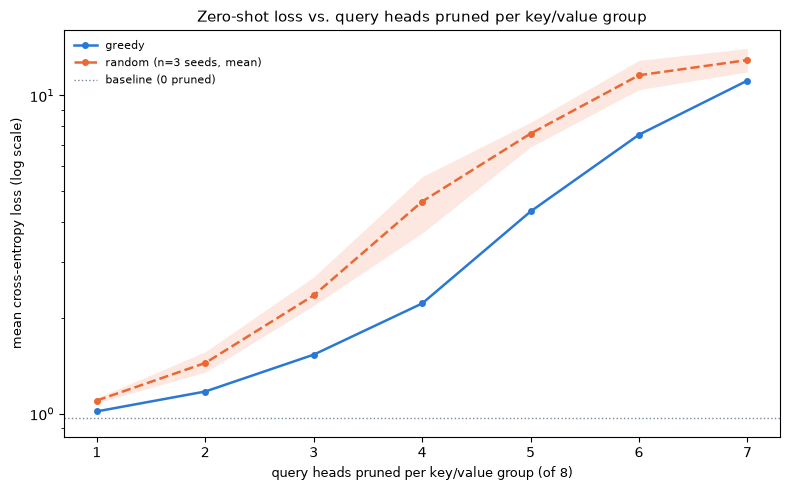

In [2]:
from bonsai.pruning.viz import plot_pruning_sweep

greedy_losses = [
    next(r["loss"] for r in results if r["strategy"] == "greedy" and r["k"] == k) for k in counts
]
random_losses = [
    [r["loss"] for r in results if r["strategy"] == "random" and r["k"] == k] for k in counts
]

fig = plot_pruning_sweep(
    counts,
    {"greedy": greedy_losses},
    random_losses,
    baseline_loss=baseline_loss,
    title="Zero-shot loss vs. query heads pruned per key/value group",
    xlabel="query heads pruned per key/value group (of 8)",
)
fig.savefig(f"{RUN_DIR}/head_pruning_sweep.png", dpi=150)
fig.savefig(f"{RUN_DIR}/head_pruning_sweep.pdf")

## Numbers behind the plot

Loss relative to baseline, as a percentage increase, alongside the total
number of query heads actually removed from the model at each count (48
layers x 4 key/value groups x $k$ per group), and the greedy/random ratio
in relative-loss terms.

In [3]:
import numpy as np

total_heads = data["num_layers"] * data["num_heads"]
random_arr = np.array(random_losses)
random_mean = random_arr.mean(axis=1)

header = f"{'k':>3}  {'total pruned':>12}  {'% of heads':>10}  {'greedy':>10}  {'random (mean)':>14}  {'ratio':>6}"
print(header)
print("-" * len(header))
for i, k in enumerate(counts):
    total = k * data["num_layers"] * data["num_key_value_heads"]
    g_rel = greedy_losses[i] / baseline_loss - 1
    r_rel = random_mean[i] / baseline_loss - 1
    ratio = r_rel / g_rel if g_rel != 0 else float("inf")
    print(
        f"{k:>3}  {total:>12}  {total / total_heads:>9.1%}  {g_rel:>+10.1%}  {r_rel:>+14.1%}  {ratio:>5.1f}x"
    )

  k  total pruned  % of heads      greedy   random (mean)   ratio
-----------------------------------------------------------------
  1           192      12.5%       +5.2%          +13.8%    2.7x
  2           384      25.0%      +21.4%          +49.3%    2.3x
  3           576      37.5%      +58.5%         +143.4%    2.5x
  4           768      50.0%     +129.6%         +380.0%    2.9x
  5           960      62.5%     +346.8%         +684.9%    2.0x
  6          1152      75.0%     +678.9%        +1097.5%    1.6x
  7          1344      87.5%    +1052.1%        +1236.4%    1.2x


## How redundant is this axis compared to depth and experts?

Compared to depth (up to ~9x greedy-vs-random separation in relative-loss
terms) and experts (2-5x), heads show the *narrowest* gap between greedy
and random -- 1.2-2.9x across the sweep, actually shrinking as $k$ grows
(2.7x at $k=1$ down to 1.2x at $k=7$).

Absolute cost is a different question, and the honest answer needs a
matched-fraction comparison against the other two sweeps, not a single
point. Depth's counts only land on 3 of heads' 7 fractions (12.5%, 25%,
50%); experts' counts land on all 7. At every one of those matched
points, expert pruning is dramatically cheaper than either heads or depth
-- e.g. at 50% pruned, greedy costs +25.5% for experts vs. +129.6% for
heads and +153.8% for depth. Heads and depth track each other closely at
all 3 shared points (12.5%: +5.2% vs.\ +8.1%; 25%: +21.4% vs.\ +21.9%;
50%: +129.6% vs.\ +153.8%), with depth's greedy loss slightly higher at
every one -- a consistent but small difference on a single-seed, 32-sample
run, not a result to lean on heavily. The robust finding is that experts
is far more redundant than either heads or depth on this model; heads and
depth look comparably (un)forgiving to prune, not obviously ranked
against each other.

## Summary

- **Greedy selection beats random at every count**, the basic sanity check
  every criterion in this project has had to clear, and `head_importance`
  clears it here too -- but by a narrower margin than either other axis,
  and the margin narrows further as more heads are pruned.
- **Experts are by far the most redundant axis pruned in this project so
  far.** At every pruned-fraction shared with the head sweep, expert
  pruning's greedy loss is a fraction of heads' or depth's (e.g. +25.5%
  vs. +129.6%/+153.8% at 50% pruned) -- a much larger gap than the one
  between heads and depth, which track each other closely.
- **Heads and depth look comparably prunable at matched fractions**, not
  clearly ranked against each other -- depth's greedy loss is slightly
  higher at all 3 points where the two sweeps' counts coincide, but the
  gap is small enough, and the run small enough (single seed, 32 samples),
  that this shouldn't be read as a strong claim either way.
- **GQA's uniform-per-group constraint** (documented in
  `bonsai.pruning.heads`) means this sweep, unlike the other two, already
  covers its entire valid search space ($k=1$ through $k=7$) rather than a
  chosen subset of a much larger range.

**What this means for Phase 2 going forward:** of the three axes now
characterized with real pruning outcomes (not just scores), experts looks
like the clear place to prune aggressively; heads and depth look roughly
equally cautious to combine in 2.4, rather than assuming every axis has
comparable headroom just because each one's greedy criterion beats random
on its own.